In [9]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import os
from typing import Annotated
import operator
from langchain_core.messages import SystemMessage, HumanMessage

In [2]:
apikey = os.getenv("GROQ_API_KEY")

In [ ]:
#generator
#evaluate
#optimize

In [4]:
generat_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)
evaluate_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)
optimize_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)

In [5]:
#evaluate => "perfect" , "need improvent" => feeback

In [6]:
from pydantic import BaseModel, Field

class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(description="Final evaluation result.")
    feedback: str = Field(description="feedback for the tweet.")

In [21]:
structured_evaluator_llm = evaluate_llm.with_structured_output(
    TweetEvaluation,
    method="json_schema"
)

In [11]:
#state

class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [22]:
def Generate_tweet(state:TweetState):
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
    Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

    Rules:
    - Do NOT use question-answer format.
    - Max 280 characters.
    - Use observational humor, irony, sarcasm, or cultural references.
    - Think in meme logic, punchlines, or relatable takes.
    - Use simple, day to day english
    """)
    ]

    response = generat_llm.invoke(messages).content
    return {"tweet":response,"tweet_history" : [response]}

def Evaluate_tweet(state:TweetState):
    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
    Evaluate the following tweet:

    Tweet: "{state['tweet']}"

    Use the criteria below to evaluate the tweet:

    1. Originality – Is this fresh, or have you seen it a hundred times before?  
    2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
    3. Punchiness – Is it short, sharp, and scroll-stopping?  
    4. Virality Potential – Would people retweet or share it?  
    5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

    Auto-reject if:
    - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
    - It exceeds 280 characters
    - It reads like a traditional setup-punchline joke
    - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

    ### Respond ONLY in structured format:
    - evaluation: "approved" or "needs_improvement"  
    - feedback: One paragraph explaining the strengths and weaknesses 
    """)
    ]
    response = structured_evaluator_llm.invoke(messages)
    return {"evaluation":response.evaluation,"feedback":response.feedback,"feedback_history":[response.feedback]}

def Optimize_tweet(state:TweetState):
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
    Improve the tweet based on this feedback:
    "{state['feedback']}"

    Topic: "{state['topic']}"
    Original Tweet:
    {state['tweet']}

    Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
    """)
        ]
    response = optimize_llm.invoke(messages).content
    iteration = state["iteration"] + 1

    return {"tweet":response,"iteration":iteration,"tweet_history" : [response]}


In [23]:
def route_evaluation(state:TweetState):
    if state['evaluation']=="approved" or state['iteration'] >= state['max_iteration']:
        return "approved"
    else:
        return "need_improvement"

In [24]:
graph = StateGraph(TweetState)

graph.add_node("Generate_tweet",Generate_tweet)
graph.add_node("Evaluate_tweet",Evaluate_tweet)
graph.add_node("Optimize_tweet",Optimize_tweet)

graph.add_edge(START,"Generate_tweet")
graph.add_edge("Generate_tweet","Evaluate_tweet")

#apprve 
#fail....
graph.add_conditional_edges("Evaluate_tweet",route_evaluation,{"approved":END,"need_improvement":"Optimize_tweet"})
graph.add_edge("Optimize_tweet","Evaluate_tweet")

workflow = graph.compile()

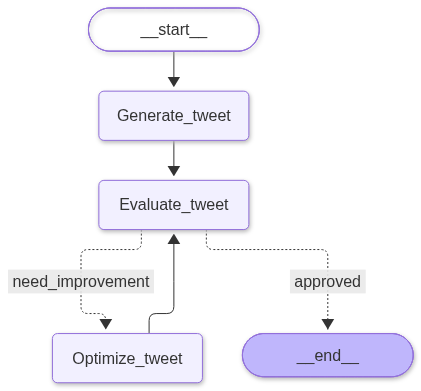

In [25]:
workflow

In [28]:
initial_state = {
    "topic": "virat kohli",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

In [30]:
result

{'topic': 'virat kohli',
 'tweet': 'Virat Kohli’s batting is like a Wi‑Fi signal: always strong, never drops, but when it does, the whole team loses. Even his coffee machine has a “Kohli mode” for extra shots. #Cricket #ViratKohli',
 'evaluation': 'approved',
 'feedback': 'The tweet lands with a clever Wi‑Fi metaphor that’s both relatable and punchy, staying well under the 280‑character limit and using relevant hashtags for reach. It’s concise, scroll‑stopping, and avoids a classic set‑up/punchline structure. The only slight drawback is that the Wi‑Fi comparison is a bit common, and the coffee‑machine line feels a touch forced, but overall the humor and originality are solid enough for a strong retweet potential.',
 'iteration': 1,
 'max_iteration': 5,
 'tweet_history': ['Virat Kohli’s batting is like a Wi‑Fi signal: always strong, never drops, but when it does, the whole team loses. Even his coffee machine has a “Kohli mode” for extra shots. #Cricket #ViratKohli'],
 'feedback_history'